# Modelo preditivo de demanda em dias úteis

**Pergunta.** Como preço e calendário explicam e permitem prever o volume diário de `Produto_A`,
em kg, nos dias úteis de um horizonte de duas semanas?

O estudo parte das hipóteses da análise exploratória de dados (EDA), compara especificações de
demanda por **validação cruzada temporal**, escolhe uma curva com WMAPE diário como critério
principal e avalia o modelo ajustado no **holdout**, reservado ao fim do processo.

A validação cruzada é feita por folds com origens semanais e ajuste expansivo. Cada fold usa
somente o passado para ajustar os coeficientes e prevê as duas semanas seguintes sem reajuste
intermediário. **Diário qualifica o erro avaliado, não a frequência dos folds ou do ajuste.**

O domínio de previsão é segunda a sexta. Os coeficientes utilizam todas as observações disponíveis
no ajuste, inclusive fins de semana; o smearing usa somente os resíduos dos dias úteis desse mesmo
ajuste. A avaliação preditiva de cada fold considera os dez dias úteis seguintes.

| Termo | Dados | Função |
|---|---|---|
| **Desenvolvimento** | 01/08/2025 a 31/10/2025, 76 observações | Base disponível para ajuste e seleção |
| **Ajuste de um fold** | Observações do desenvolvimento anteriores à origem | Estimar coeficientes; calcular smearing nos dias úteis |
| **Validação cruzada temporal** | Seis folds com origens semanais; dez dias úteis avaliados por fold | Comparar e selecionar as especificações |
| **Holdout** | 03/11/2025 a 14/11/2025, dez dias úteis | Avaliação final após ajuste e congelamento |

O termo **holdout** é usado em todo o texto para esse conjunto final. Uma perda relevante de
desempenho nessa avaliação pode motivar investigação e revisão do modelo.

**Escopo de calendário.** A aplicação planeja dez dias de segunda a sexta, uma delimitação explícita deste estudo. O histórico contém vendas em dez dias de fim de semana; ausência de registros nos demais dias não significa volume zero nem comprova que a operação esteja fechada. O enunciado pede duas semanas e não exclui fins de semana expressamente. A cobertura do holdout coincide com dez dias úteis, mas não prova a regra comercial. Uma aplicação com vendas planejadas no sábado ou domingo exige ampliar calendário, validação e calibração; a curva publicada atualmente rejeita esses dias.

**Guia das figuras.** A Figura 2.1 apresenta os folds; a Figura 2.2 compara os candidatos; a Figura 2.3 mostra diagnósticos; a Figura 2.4 mostra curvas dentro das faixas observadas; a Figura 2.5 apresenta o holdout histórico.

## 1. Hipóteses e candidatos

A EDA identifica associação negativa entre preço e volume, diferenças de nível por dia da semana,
dispersão dentro das faixas de preço e concentração de alguns episódios em períodos específicos.
Esses achados motivam os candidatos abaixo; a escolha é feita pela previsão fora da amostra na
validação cruzada temporal.

| Hipótese a examinar | Representação candidata |
|---|---|
| O volume diminui com o preço, com elasticidade constante | Potência: `ln(volume) ~ ln(preço)` |
| O calendário desloca o nível de demanda | Sem calendário, dia útil/fim de semana, sete dias ou grupos parcimoniosos |
| Segunda a quinta podem compartilhar um nível; sexta tem outro | Agrupamento de calendário de `P3` |
| A segunda-feira pode exigir um nível próprio | Agrupamento de calendário de `P4` |
| Outra forma funcional pode prever bem | Exponencial e linear com o calendário de `P3` |
| Uma tendência temporal pode melhorar a previsão | Curva de potência com tendência, somente como sensibilidade |

Os grupos de calendário são hipóteses de representação, não efeitos causais demonstrados.
Defasagens de volume ficam fora desta especificação: o estudo recebe preço e contexto conhecido
do dia, sem criar uma dinâmica recursiva de volume.

## 2. Protocolo da validação cruzada temporal e regra de escolha

1. **Folds.** A origem de cada fold é uma segunda-feira do desenvolvimento com pelo menos
   30 observações anteriores e as duas semanas de dias úteis completas no desenvolvimento.
   O ajuste é expansivo e usa todas as observações anteriores à origem. O horizonte tem 14 dias
   corridos; somente seus dez dias úteis entram nas métricas. Não há embaralhamento nem
   atualização dentro do horizonte.
2. **Smearing.** Para potência e exponencial, calcula-se a média dos resíduos exponenciados
   **somente nos dias úteis do ajuste daquele fold**. O fator não é fixado antecipadamente
   e não utiliza os volumes do horizonte avaliado. A forma linear não usa smearing.
3. **Elegibilidade.** A inclinação de preço deve ser negativa em todos os folds e as previsões
   devem ser positivas em todos os dias avaliados. `T1`, com tendência, é uma sensibilidade e
   não participa da seleção.
4. **Métrica principal.** WMAPE diário: soma dos erros absolutos diários dividida pela soma dos
   volumes observados no fold. As métricas complementares são RMSE, viés e WMAPE semanal.
   Este último agrega os volumes por semana antes de calcular os erros absolutos.
5. **Resumo.** A seleção usa a média dos indicadores dos seis folds, dando o mesmo peso a cada
   origem. Esse resumo não é a média dos erros percentuais de cada dia nem um único WMAPE
   calculado sobre todas as previsões empilhadas.
6. **Zona de equivalência prática.** Entram os candidatos elegíveis com WMAPE diário médio até
   2 pontos percentuais acima do menor e RMSE médio até 5% acima do menor. Essa faixa é uma regra
   operacional de seleção, não um teste estatístico de equivalência.
7. **Desempate.** Menos parâmetros; com igual número de parâmetros, preferência pela potência,
   que oferece elasticidade diretamente interpretável; persistindo o empate, menor WMAPE diário.
8. **Holdout.** É carregado na seção final, após selecionar, ajustar e salvar o modelo.

Como origens consecutivas estão separadas por uma semana e os horizontes têm duas semanas,
existem datas avaliadas em mais de um fold. Os folds não devem ser tratados como amostras
independentes para uma afirmação de significância.

O protocolo de origens temporais e horizontes futuros segue o princípio de validação de séries temporais de Hyndman e Athanasopoulos (2021, seção 5.10). As hipóteses de calendário foram propostas usando o desenvolvimento completo: a comparação é condicional a esse catálogo, não uma avaliação aninhada de todo o processo exploratório.

In [1]:
from pathlib import Path
import json
import os
import sys

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

from src.modeling.demand_curve import (
    file_sha256, model_core_sha256, predict_volume_from_artifact, save_artifact,
    validate_artifact,
)

DATA_PATH = ROOT / 'data/processed/minerva_modelagem_treino.csv'
HOLDOUT_PATH = ROOT / 'data/interim/minerva_holdout.csv'
FIGURES_DIR = ROOT / 'reports/figures/preditivo_diario'
TABLES_DIR = ROOT / 'reports/tables/preditivo_diario'
MODELO_PATH = ROOT / 'models/preditivo_diario/curva_demanda.json'
for directory in [FIGURES_DIR, TABLES_DIR, MODELO_PATH.parent]:
    directory.mkdir(parents=True, exist_ok=True)

ORDEM_DIAS = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
DIAS_UTEIS = ORDEM_DIAS[:5]

# Regra de decisão da seção 2
MINIMO_AJUSTE = 30
HORIZONTE_DIAS = 14
ZONA_WMAPE_DIARIO = 0.02
ZONA_RMSE = 0.05
CONCORRENTES = ['P0', 'P1', 'P2', 'P3', 'P4', 'E1', 'L1']

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 40)
from src.modeling.benchmarks import weekday_mean_forecast


# Numeração local de tabelas e figuras desta etapa.
from IPython.display import Markdown, display
_num_tabela = 0
_num_figura = 0

def exibir_tabela(objeto, titulo):
    global _num_tabela
    _num_tabela += 1
    display(Markdown(f"**Tabela 2.{_num_tabela}.** {titulo}. Unidades indicadas nas colunas; fonte: cálculo deste notebook."))
    display(objeto)

def legendar_figura(titulo):
    global _num_figura
    _num_figura += 1
    display(Markdown(f"**Figura 2.{_num_figura}.** {titulo}. Fonte: cálculo deste notebook; eixos indicam as unidades."))


2026-11-08 19:01:18.136 | INFO     | src.config:<module>:11 - PROJ_ROOT path is: /Users/ngodeny/Documents/mestrado/202602-resolucao_problemas


## 3. Desenvolvimento e construção dos folds

**Pergunta.** Quais observações entram no ajuste e na avaliação de cada fold?

**Método.** Apenas o desenvolvimento é carregado. Cada origem define um fold, cujo ajuste contém
as observações anteriores à origem. A avaliação contém somente os dez dias úteis do horizonte
seguinte. A tabela e o gráfico mostram essa separação cronológica; o holdout permanece separado.

**Tabela 2.1.** Calendário dos folds. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,Origem,Ajuste até,Observações de ajuste,Dias úteis de ajuste,Avaliação até,Dias úteis avaliados,Volume observado no fold (kg)
Fold,,,,,,,
1,2025-09-15,2025-09-12,34,31,2025-09-26,10,158.54
2,2025-09-22,2025-09-19,39,36,2025-10-03,10,143.29
3,2025-09-29,2025-09-28,46,41,2025-10-10,10,310.32
4,2025-10-06,2025-10-05,52,46,2025-10-17,10,526.63
5,2025-10-13,2025-10-11,58,51,2025-10-24,10,371.60
6,2025-10-20,2025-10-19,65,56,2025-10-31,10,143.43


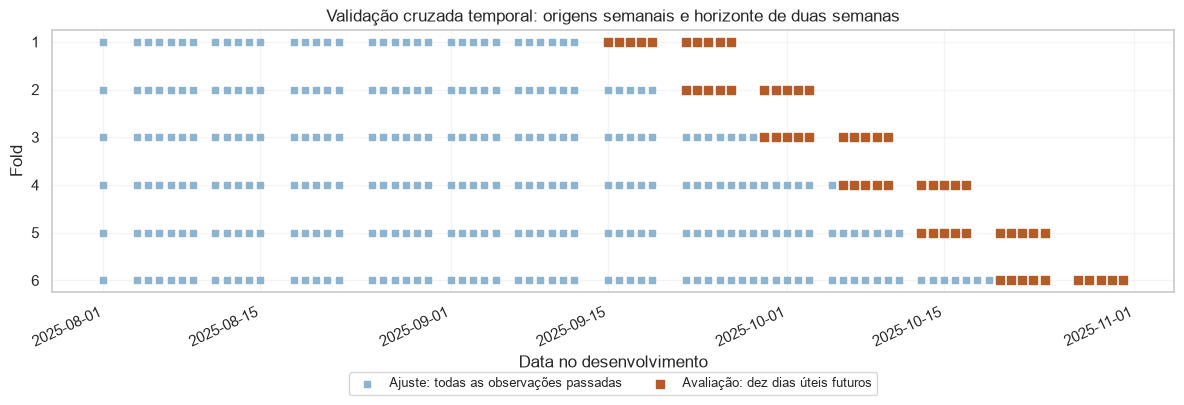

**Figura 2.1.** Seis origens semanais; ajuste somente no passado e avaliação de dez dias úteis futuros por fold. Fonte: cálculo deste notebook; eixos indicam as unidades.

In [2]:
dados = pd.read_csv(DATA_PATH, parse_dates=['data', 'inicio_semana'])
dados = dados.sort_values('data').reset_index(drop=True)
if dados['data'].duplicated().any():
    raise ValueError('Há datas duplicadas no desenvolvimento.')
if (dados[['volume_kg', 'preco_kg']] <= 0).any().any():
    raise ValueError('Volume e preço devem ser positivos.')
assert dados['data'].max() == pd.Timestamp('2025-10-31')
dados['ln_volume'] = np.log(dados['volume_kg'])
dados['ln_preco'] = np.log(dados['preco_kg'])

def dias_do_fold(base, origem):
    return base.loc[
        (base['data'] >= origem)
        & (base['data'] < origem + pd.Timedelta(days=HORIZONTE_DIAS))
        & base['dia_semana'].isin(DIAS_UTEIS)
    ]

ultima_data = dados['data'].max()
origens = []
for origem in dados.loc[dados['dia_semana'] == 'Segunda', 'data']:
    ajuste = dados.loc[dados['data'] < origem]
    if len(ajuste) >= MINIMO_AJUSTE and origem + pd.Timedelta(days=11) <= ultima_data:
        if set(ajuste['dia_semana']) != set(ORDEM_DIAS):
            raise ValueError(f'Ajuste sem todos os dias da semana na origem {origem.date()}.')
        origens.append(origem)

linhas = []
for numero, origem in enumerate(origens, start=1):
    ajuste = dados.loc[dados['data'] < origem]
    avaliacao = dias_do_fold(dados, origem)
    assert ajuste['data'].max() < avaliacao['data'].min()
    assert len(avaliacao) == 10 and avaliacao['inicio_semana'].nunique() == 2
    linhas.append({
        'Fold': numero, 'Origem': origem.date(),
        'Ajuste até': ajuste['data'].max().date(),
        'Observações de ajuste': len(ajuste),
        'Dias úteis de ajuste': int(ajuste['dia_semana'].isin(DIAS_UTEIS).sum()),
        'Avaliação até': avaliacao['data'].max().date(),
        'Dias úteis avaliados': len(avaliacao),
        'Volume observado no fold (kg)': float(avaliacao['volume_kg'].sum()),
    })
tabela_origens = pd.DataFrame(linhas).set_index('Fold')
tabela_origens.to_csv(TABLES_DIR / 'calendario_validacao_cruzada.csv')
exibir_tabela(tabela_origens.round(2), 'Calendário dos folds')

fig, ax = plt.subplots(figsize=(12, 4.3))
for numero, origem in enumerate(origens, start=1):
    ajuste = dados.loc[dados['data'] < origem]
    avaliacao = dias_do_fold(dados, origem)
    ax.scatter(ajuste['data'], np.full(len(ajuste), numero), marker='s', s=20,
               color='#8cb3cf', label='Ajuste: todas as observações passadas' if numero == 1 else None)
    ax.scatter(avaliacao['data'], np.full(len(avaliacao), numero), marker='s', s=30,
               color='#b35c28', label='Avaliação: dez dias úteis futuros' if numero == 1 else None)
ax.set(yticks=range(1, len(origens) + 1), ylabel='Fold', xlabel='Data no desenvolvimento',
       title='Validação cruzada temporal: origens semanais e horizonte de duas semanas')
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=9)
ax.grid(alpha=.2)
fig.autofmt_xdate(rotation=25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'calendario_folds.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Seis origens semanais; ajuste somente no passado e avaliação de dez dias úteis futuros por fold')

**Resultado dos folds.** O protocolo produz seis origens semanais, de 15/09 a 20/10/2025.
O ajuste cresce de 34 para 65 observações, enquanto cada avaliação contém dez dias
úteis em cada horizonte e duas semanas. Todas as janelas de ajuste contêm os sete dias da semana, permitindo
estimar as codificações de calendário propostas.

Os volumes observados diferem entre os folds. Isso descreve diferenças entre períodos, mas não
permite antecipar qual deles terá maior erro relativo. Essa comparação depende das previsões,
apresentadas a seguir.

## 4. Candidatos e execução da validação cruzada temporal

**Pergunta.** Quais formas funcionais e representações de calendário conseguem prever os dias
úteis de duas semanas, usando somente dados anteriores à origem?

| Código | Forma | Calendário no ajuste |
|---|---|---|
| `P0` | Potência | Nenhum |
| `P1` | Potência | Dia útil e fim de semana |
| `P2` | Potência | Sete dias da semana |
| `P3` | Potência | Segunda–quinta, sexta e fim de semana |
| `P4` | Potência | Segunda, terça–quinta, sexta e fim de semana |
| `E1` | Exponencial | Igual a `P3` |
| `L1` | Linear | Igual a `P3` |
| `T1` | Potência com tendência | Igual a `P3`; somente sensibilidade |

Na potência, ajusta-se `ln(volume) ~ ln(preço) + calendário`. Na exponencial, o preço entra
como `preço/100`; na linear, a resposta é o próprio volume. Potência e exponencial recebem
smearing estimado exclusivamente nos resíduos dos dias úteis de cada ajuste. A mesma política
de calibração e os mesmos folds são aplicados a todos os candidatos.

In [3]:
MAPAS_CONTEXTO = {
    'none': {dia: 'Geral' for dia in ORDEM_DIAS},
    'weekend': {
        dia: ('Fim_de_semana' if dia in ['Sábado', 'Domingo'] else 'Dia_util')
        for dia in ORDEM_DIAS
    },
    'weekday': {dia: dia for dia in ORDEM_DIAS},
    'grouped': {
        dia: (
            'Segunda_a_Quinta' if dia in ORDEM_DIAS[:4]
            else 'Sexta' if dia == 'Sexta'
            else 'Fim_de_semana'
        )
        for dia in ORDEM_DIAS
    },
    'grouped4': {
        dia: (
            'Segunda' if dia == 'Segunda'
            else 'Terca_a_Quinta' if dia in ORDEM_DIAS[1:4]
            else 'Sexta' if dia == 'Sexta'
            else 'Fim_de_semana'
        )
        for dia in ORDEM_DIAS
    },
}
ORDEM_CONTEXTO = {
    'none': ['Geral'],
    'weekend': ['Dia_util', 'Fim_de_semana'],
    'weekday': ORDEM_DIAS,
    'grouped': ['Segunda_a_Quinta', 'Sexta', 'Fim_de_semana'],
    'grouped4': ['Terca_a_Quinta', 'Segunda', 'Sexta', 'Fim_de_semana'],
}
FAMILIAS_LOG = {'power', 'exponential'}


def especificacao(family='power', calendar='grouped', trend=False):
    return {'family': family, 'calendar': calendar, 'trend': trend}


CANDIDATOS = {
    'P0': especificacao(calendar='none'),
    'P1': especificacao(calendar='weekend'),
    'P2': especificacao(calendar='weekday'),
    'P3': especificacao(),
    'P4': especificacao(calendar='grouped4'),
    'E1': especificacao(family='exponential'),
    'L1': especificacao(family='linear'),
    'T1': especificacao(trend=True),
}


def matriz_desenho(base, spec):
    if spec['family'] == 'power':
        preco = base['ln_preco'].astype(float).rename('ln_preco')
    else:
        preco = (base['preco_kg'].astype(float) / 100).rename('preco_100')
    matriz = pd.DataFrame({'const': 1.0, preco.name: preco}, index=base.index)
    contexto = base['dia_semana'].map(MAPAS_CONTEXTO[spec['calendar']])
    for nome in ORDEM_CONTEXTO[spec['calendar']][1:]:
        matriz[f'contexto_{nome}'] = (contexto == nome).astype(float)
    if spec['trend']:
        matriz['indice_tempo_10'] = base['indice_tempo'].astype(float) / 10
    return matriz


def ajustar(ajuste, spec):
    log = spec['family'] in FAMILIAS_LOG
    resposta = ajuste['ln_volume'] if log else ajuste['volume_kg']
    modelo = sm.OLS(resposta, matriz_desenho(ajuste, spec)).fit()
    dias_uteis_ajuste = ajuste['dia_semana'].isin(DIAS_UTEIS)
    if not dias_uteis_ajuste.any():
        raise ValueError('O ajuste precisa conter dias úteis para calibrar a previsão.')
    smearing = float(np.exp(modelo.resid.loc[dias_uteis_ajuste]).mean()) if log else 1.0
    return modelo, smearing


def prever(modelo, smearing, base, spec):
    if not base['dia_semana'].isin(DIAS_UTEIS).all():
        raise ValueError('A calibração preditiva deste estudo é restrita a dias úteis.')
    linear = np.asarray(modelo.predict(matriz_desenho(base, spec)), dtype=float)
    return np.exp(linear) * smearing if spec['family'] in FAMILIAS_LOG else linear


def painel_erros(previsoes):
    real = previsoes['volume_real_kg']
    previsto = previsoes['volume_previsto_kg']
    erro = previsto - real
    semanal = previsoes.groupby('inicio_semana')[['volume_real_kg', 'volume_previsto_kg']].sum()
    erro_semanal = semanal['volume_previsto_kg'] - semanal['volume_real_kg']
    return {
        'WMAPE diário': float(erro.abs().sum() / real.sum()),
        'MAE': float(erro.abs().mean()),
        'RMSE': float(np.sqrt(np.mean(erro**2))),
        'Erro absoluto mediano': float(erro.abs().median()),
        'Viés': float(erro.sum() / real.sum()),
        'WMAPE semanal': float(erro_semanal.abs().sum() / semanal['volume_real_kg'].sum()),
        'Pior erro semanal (%)': float((erro_semanal.abs() / semanal['volume_real_kg']).max()),
        'Previsão mínima': float(previsto.min()),
    }


def validar(code, spec):
    previsoes, coeficientes = [], []
    for numero, origem in enumerate(origens, start=1):
        ajuste = dados.loc[dados['data'] < origem]
        horizonte = dias_do_fold(dados, origem)
        assert ajuste['data'].max() < horizonte['data'].min()
        assert horizonte['dia_semana'].isin(DIAS_UTEIS).all()
        modelo, smearing = ajustar(ajuste, spec)
        previsoes.append(pd.DataFrame({
            'candidato': code, 'fold': numero, 'origem': origem,
            'ajuste_ate': ajuste['data'].max(),
            'data': horizonte['data'].to_numpy(),
            'inicio_semana': horizonte['inicio_semana'].to_numpy(),
            'dia_semana': horizonte['dia_semana'].to_numpy(),
            'preco_kg': horizonte['preco_kg'].to_numpy(),
            'volume_real_kg': horizonte['volume_kg'].to_numpy(),
            'volume_previsto_kg': prever(modelo, smearing, horizonte, spec),
        }))
        coeficientes.append({
            'candidato': code, 'fold': numero, 'origem': origem.date(),
            'ajuste_ate': ajuste['data'].max().date(),
            'observacoes_ajuste': len(ajuste),
            'dias_uteis_smearing': int(ajuste['dia_semana'].isin(DIAS_UTEIS).sum()),
            'smearing': smearing,
            'Inclinação de preço': float(modelo.params.iloc[1]),
        })
    return pd.concat(previsoes, ignore_index=True), pd.DataFrame(coeficientes)


previsoes_validacao, coeficientes_rodada, linhas_metricas = [], [], []
for code, spec in CANDIDATOS.items():
    previsoes, coeficientes = validar(code, spec)
    previsoes_validacao.append(previsoes)
    coeficientes_rodada.append(coeficientes)
    for fold, recorte in previsoes.groupby('fold'):
        linhas_metricas.append({
            'Código': code, 'Fold': fold, 'Origem': recorte['origem'].iloc[0].date(),
            **painel_erros(recorte),
        })
previsoes_validacao = pd.concat(previsoes_validacao, ignore_index=True)
coeficientes_rodada = pd.concat(coeficientes_rodada, ignore_index=True)
metricas_rodada = pd.DataFrame(linhas_metricas)

parametros = {code: matriz_desenho(dados, spec).shape[1] for code, spec in CANDIDATOS.items()}
wmape_diario_fold = 100 * metricas_rodada.pivot(
    index='Origem', columns='Código', values='WMAPE diário'
)[list(CANDIDATOS)]
print('WMAPE diário (%) por fold da validação cruzada temporal')
exibir_tabela(wmape_diario_fold.round(2), 'WMAPE diário por origem e candidato (%)')
coeficientes_rodada.to_csv(TABLES_DIR / 'parametros_por_fold.csv', index=False)
assert previsoes_validacao['dia_semana'].isin(DIAS_UTEIS).all()
assert (pd.to_datetime(previsoes_validacao['ajuste_ate']) < previsoes_validacao['origem']).all()
assert (previsoes_validacao['data'] >= previsoes_validacao['origem']).all()
assert previsoes_validacao['data'].max() <= dados['data'].max()

WMAPE diário (%) por fold da validação cruzada temporal


**Tabela 2.2.** WMAPE diário por origem e candidato (%). Unidades indicadas nas colunas; fonte: cálculo deste notebook.

Código,P0,P1,P2,P3,P4,E1,L1,T1
Origem,,,,,,,,
2025-09-15,33.75,38.56,35.31,27.86,28.19,27.80,30.97,52.77
2025-09-22,55.85,56.48,47.55,45.96,45.74,45.89,46.92,92.27
2025-09-29,53.40,54.57,41.00,38.03,40.49,38.35,43.00,34.83
2025-10-06,63.70,62.93,43.13,43.49,43.64,43.89,51.05,54.52
2025-10-13,67.44,59.90,42.06,38.79,40.00,38.80,42.84,38.91
2025-10-20,44.43,33.31,41.63,26.99,36.67,26.33,61.20,32.67


**Resultado da validação cruzada temporal.** O WMAPE diário de `P3` varia entre aproximadamente
26,99% e 45,96% nos seis folds. Isso significa que a precisão relativa muda entre as janelas
avaliadas. `P3` e `E1` apresentam erros médios próximos e aumentos de erro em algumas das mesmas
origens. Essa coincidência descreve o desempenho observado; não identifica sua causa nem permite
atribuir o erro exclusivamente ao período ou excluir limitações dos modelos.

## 5. Comparação dos candidatos e escolha

**Pergunta.** Qual candidato será selecionado pela regra estabelecida na seção 2?

**Método.** O painel apresenta média e desvio-padrão (DP) entre folds, priorizando WMAPE diário.
O DP descreve a variação dos erros entre origens; não é intervalo de confiança nem teste de
diferença entre candidatos. A zona de equivalência prática usa os limites de WMAPE diário e
RMSE, e o desempate favorece parcimônia e interpretação da elasticidade.

As colunas de inclinação mostram o menor e o maior coeficiente de preço obtidos entre os folds,
e a indicação **Negativa em todos os folds** explicita esse critério de elegibilidade. Esses valores
se referem aos ajustes da validação cruzada temporal, anteriores ao ajuste final da seção 6.

A escala depende da forma funcional: na potência, o coeficiente representa a elasticidade; na
exponencial, a variação de `ln(volume)` por R$ 100/kg de aumento no preço; na linear, a variação
do volume em kg por R$ 100/kg de aumento no preço. As magnitudes não são diretamente comparáveis
entre famílias; a verificação comum exige sinal negativo em todos os folds.

**Tabela 2.3.** Comparação dos candidatos na validação temporal. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,Parâmetros,Inclinação mínima (VC),Inclinação máxima (VC),Negativa em todos os folds,WMAPE diário (%),DP diário (p.p.),RMSE (kg),Viés (%),WMAPE semanal (%),Pior erro semanal (%),Previsão mínima (kg),Válido,Concorre,Na zona de equivalência
Código,,,,,,,,,,,,,,
E1,4,-0.865,-0.519,True,36.844,8.122,14.196,-0.307,34.139,42.750,3.092,True,True,True
P3,4,-10.876,-6.625,True,36.854,7.878,14.140,0.061,34.226,42.766,3.198,True,True,True
P4,5,-11.356,-6.596,True,39.120,6.202,14.618,0.866,34.298,42.739,3.057,True,True,False
P2,8,-11.032,-4.629,True,41.780,3.943,15.083,2.104,35.844,44.221,3.136,True,True,False
L1,4,-30.924,-8.467,True,45.999,10.023,16.653,-11.169,39.733,51.317,-23.515,False,True,False
P1,3,-9.455,-3.537,True,50.956,12.101,18.798,-3.275,39.159,45.896,11.923,True,True,False
T1,5,-11.651,-6.736,True,50.996,22.193,16.955,13.120,49.512,64.984,3.481,True,False,False
P0,2,-9.839,-2.249,True,53.095,12.452,19.420,-3.260,39.947,47.600,15.527,True,True,False


Candidatos na zona de equivalência: ['P3', 'E1']
Escolhido pela regra: P3


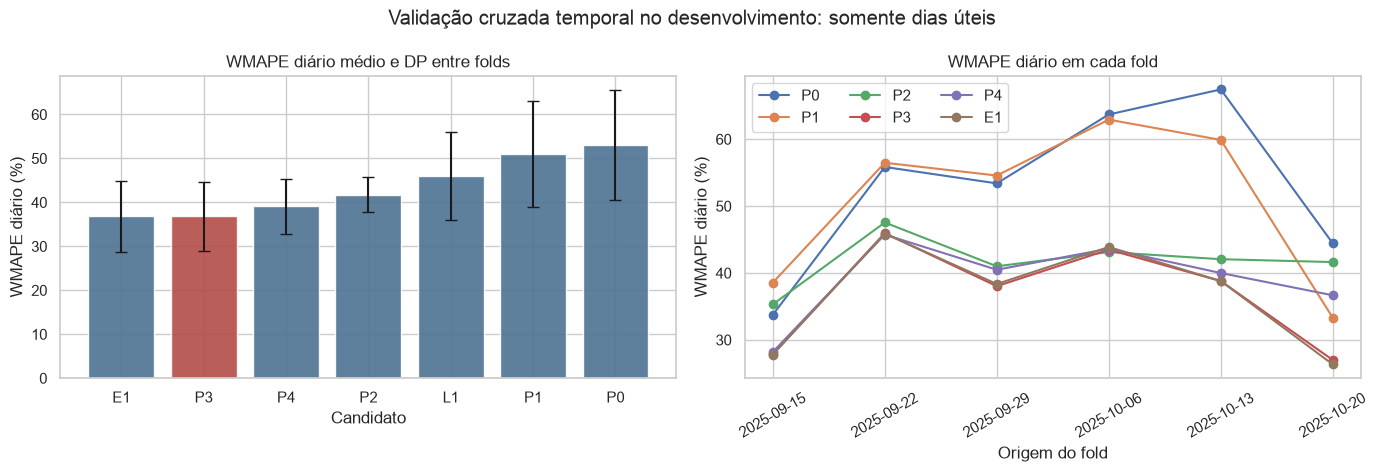

**Figura 2.2.** WMAPE diário médio e por fold; barras de erro são desvios-padrão entre origens, sem interpretação de IC. Fonte: cálculo deste notebook; eixos indicam as unidades.

In [4]:
media = metricas_rodada.groupby('Código').mean(numeric_only=True)
desvio = metricas_rodada.groupby('Código').std(numeric_only=True)
inclinacoes = coeficientes_rodada.groupby('candidato')['Inclinação de preço']

painel = pd.DataFrame(index=list(CANDIDATOS))
painel['Parâmetros'] = pd.Series(parametros)
painel['Inclinação mínima (VC)'] = inclinacoes.min()
painel['Inclinação máxima (VC)'] = inclinacoes.max()
painel['Negativa em todos os folds'] = inclinacoes.max() < 0
painel['WMAPE diário (%)'] = 100 * media['WMAPE diário']
painel['DP diário (p.p.)'] = 100 * desvio['WMAPE diário']
painel['RMSE (kg)'] = media['RMSE']
painel['Viés (%)'] = 100 * media['Viés']
painel['WMAPE semanal (%)'] = 100 * media['WMAPE semanal']
painel['Pior erro semanal (%)'] = 100 * media['Pior erro semanal (%)']
painel['Previsão mínima (kg)'] = metricas_rodada.groupby('Código')['Previsão mínima'].min()
painel['Válido'] = (inclinacoes.max() < 0) & (painel['Previsão mínima (kg)'] > 0)
painel['Concorre'] = painel.index.isin(CONCORRENTES)
painel.index.name = 'Código'

def aplicar_regra(painel):
    elegiveis = painel.loc[painel['Válido'] & painel['Concorre']]
    melhor_wmape = elegiveis['WMAPE diário (%)'].min()
    melhor_rmse = elegiveis['RMSE (kg)'].min()
    painel = painel.copy()
    painel['Na zona de equivalência'] = (
        painel['Válido'] & painel['Concorre']
        & (painel['WMAPE diário (%)'] <= melhor_wmape + 100 * ZONA_WMAPE_DIARIO)
        & (painel['RMSE (kg)'] <= melhor_rmse * (1 + ZONA_RMSE))
    )
    zona = painel.loc[painel['Na zona de equivalência']].copy()
    zona['potencia_primeiro'] = (~zona.index.isin(
        [c for c, s in CANDIDATOS.items() if s['family'] == 'power']
    )).astype(int)
    zona = zona.sort_values(['Parâmetros', 'potencia_primeiro', 'WMAPE diário (%)'])
    if zona.empty:
        raise ValueError('Não há candidato na zona de equivalência definida.')
    return painel.sort_values('WMAPE diário (%)'), zona.index[0], zona

painel, ESCOLHIDO, zona = aplicar_regra(painel)
painel.to_csv(TABLES_DIR / 'comparacao_candidatos.csv')
metricas_rodada.to_csv(TABLES_DIR / 'metricas_validacao_cruzada.csv', index=False)
previsoes_validacao.to_csv(TABLES_DIR / 'previsoes_validacao_cruzada.csv', index=False)
exibir_tabela(painel.round(3), 'Comparação dos candidatos na validação temporal')
print(f'Candidatos na zona de equivalência: {list(zona.index)}')
print(f'Escolhido pela regra: {ESCOLHIDO}')
assert not CANDIDATOS[ESCOLHIDO]['trend'] and CANDIDATOS[ESCOLHIDO]['family'] != 'linear'
ESPECIFICACAO = CANDIDATOS[ESCOLHIDO]

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8))
ordem = [c for c in painel.index if painel.loc[c, 'Concorre']]
eixos[0].bar(ordem, painel.loc[ordem, 'WMAPE diário (%)'],
             yerr=painel.loc[ordem, 'DP diário (p.p.)'], capsize=4,
             color=['#b24c46' if c == ESCOLHIDO else '#4c7292' for c in ordem], alpha=.9)
eixos[0].set(title='WMAPE diário médio e DP entre folds', xlabel='Candidato', ylabel='WMAPE diário (%)')
for candidato in ['P0', 'P1', 'P2', 'P3', 'P4', 'E1']:
    eixos[1].plot(wmape_diario_fold.index.astype(str), wmape_diario_fold[candidato],
                  marker='o', label=candidato)
eixos[1].set(title='WMAPE diário em cada fold', xlabel='Origem do fold', ylabel='WMAPE diário (%)')
eixos[1].tick_params(axis='x', rotation=30)
eixos[1].legend(ncol=3)
fig.suptitle('Validação cruzada temporal no desenvolvimento: somente dias úteis')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'comparacao_candidatos.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('WMAPE diário médio e por fold; barras de erro são desvios-padrão entre origens, sem interpretação de IC')

**Resultado do painel.** `E1` e `P3` têm WMAPE diário médio próximo de 36,85%. Os valores de
`P4` e `P2` são aproximadamente 39,12% e 41,78%. As diferenças de médias são descritas pela tabela;
não foi realizado um teste formal de superioridade entre modelos.

O limite da zona de equivalência prática é aproximadamente **38,84% de WMAPE diário** e
**14,85 kg de RMSE**. `P3` e `E1` atendem aos dois critérios. `P4` ultrapassa o limite diário,
apesar de ter RMSE dentro da faixa. Todos os candidatos apresentam inclinação negativa nos seis
folds. `L1` não atende à elegibilidade porque produz previsões negativas. `T1` permanece como
sensibilidade e não participa da seleção.

O WMAPE semanal permanece como indicador complementar de erro nos totais. Ele permite avaliar
a grandeza associada às metas sem esconder a distribuição diária usada na escolha.

**Escolha.** A regra seleciona **`P3`**, uma curva de potência com elasticidade compartilhada e
três níveis de calendário no ajuste, com quatro parâmetros. `P3` e `E1` têm o mesmo número de
parâmetros e pertencem à zona de equivalência prática; o desempate favorece a potência pela
interpretação direta da elasticidade. Isso não é uma afirmação de superioridade estatística.

O uso da segunda a quinta em um único nível é uma escolha de representação parcimoniosa dentro
dos candidatos avaliados. A aplicação preditiva e sua calibração são restritas aos dias úteis.

### 5.1 Referência de calendário sem preço

O benchmark usa a média do volume de cada dia da semana nas observações anteriores à origem, sem consultar preço ou volume futuro. É calculado nos mesmos seis folds e dez dias úteis por horizonte (Hyndman e Athanasopoulos, 2021, seção 5.2). Por ter sido acrescentado nesta revisão, serve como comparação descritiva adicional e não altera a seleção já declarada de `P3`. A média dos WMAPEs por origem não deve ser confundida com um único WMAPE sobre previsões empilhadas.

In [5]:
benchmark_predictions = []
benchmark_metrics = []
for fold, origin in enumerate(origens, start=1):
    history = dados.loc[dados['data'] < origin]
    horizon_b = dias_do_fold(dados, origin)
    prediction_b = weekday_mean_forecast(history, horizon_b[['data', 'dia_semana']])
    frame_b = pd.DataFrame({
        'candidato': 'Media_dia_semana', 'fold': fold, 'origem': origin,
        'ajuste_ate': history['data'].max(), 'data': horizon_b['data'].to_numpy(),
        'inicio_semana': horizon_b['inicio_semana'].to_numpy(),
        'dia_semana': horizon_b['dia_semana'].to_numpy(),
        'volume_real_kg': horizon_b['volume_kg'].to_numpy(),
        'volume_previsto_kg': prediction_b,
    })
    benchmark_predictions.append(frame_b)
    benchmark_metrics.append({'Fold': fold, 'Origem': origin, **painel_erros(frame_b)})
benchmark_predictions = pd.concat(benchmark_predictions, ignore_index=True)
benchmark_metrics = pd.DataFrame(benchmark_metrics)
benchmark_predictions.to_csv(TABLES_DIR / 'previsoes_benchmark_calendario.csv', index=False)
benchmark_metrics.to_csv(TABLES_DIR / 'metricas_benchmark_calendario.csv', index=False)
exibir_tabela(benchmark_metrics.round(4), 'Métricas do benchmark sem preço por fold')
baseline_wmape = 100 * benchmark_metrics['WMAPE diário'].mean()
p3_wmape = float(painel.loc['P3', 'WMAPE diário (%)'])
display(Markdown(
    f'**Resultado do benchmark.** Média por dia da semana: **{baseline_wmape:.2f}%**; '
    f'P3: **{p3_wmape:.2f}%**, uma diferença de **{baseline_wmape-p3_wmape:.2f} pontos percentuais**. '
    'A comparação indica contribuição preditiva da especificação com preço nesses folds; '
    'não identifica o efeito causal de alterar preços.'
))

/var/folders/6g/yn7cwj_52f72rdbklyyb3hsh0000gn/T/ipykernel_66279/2151964890.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  exibir_tabela(benchmark_metrics.round(4), 'Métricas do benchmark sem preço por fold')


**Tabela 2.4.** Métricas do benchmark sem preço por fold. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,Fold,Origem,WMAPE diário,MAE,RMSE,Erro absoluto mediano,Viés,WMAPE semanal,Pior erro semanal (%),Previsão mínima
0,1,2025-09-15,0.4621,7.3253,8.6717,5.9850,0.4210,0.4210,0.6894,8.0474
1,2,2025-09-22,0.5380,7.7085,8.9820,6.5673,0.5309,0.5309,0.6450,8.0004
2,3,2025-09-29,0.5208,16.1619,22.2059,9.9557,-0.3273,0.5062,0.5534,7.3837
3,4,2025-10-06,0.6152,32.4000,39.2007,37.1432,-0.6152,0.6152,0.6541,7.2326
4,5,2025-10-13,0.6021,22.3723,32.0207,16.8745,-0.3840,0.5765,0.6093,8.2056
5,6,2025-10-20,0.8438,12.1022,15.5821,9.5970,0.8223,0.8223,1.0183,8.1718


**Resultado do benchmark.** Média por dia da semana: **59.70%**; P3: **36.85%**, uma diferença de **22.85 pontos percentuais**. A comparação indica contribuição preditiva da especificação com preço nesses folds; não identifica o efeito causal de alterar preços.

## 6. Ajuste final e calibração para dias úteis

**Pergunta.** Quais parâmetros e qual correção de retransformação serão usados na previsão?

**Método.** A especificação escolhida é ajustada às 76 observações do desenvolvimento. O smearing
é calculado nos 66 resíduos de dias úteis desse ajuste. Os erros-padrão HC3 quantificam a incerteza
dos coeficientes; eles não corrigem o valor previsto em kg. A calibração usa um único fator para
os dias úteis, sem assumir que isso elimina toda heterogeneidade residual dentro desse domínio.

A retransformação segue Duan (1983); a covariância HC3 segue MacKinnon e White (1985). HC3 altera a inferência sobre os coeficientes, sem tornar o ajuste de mínimos quadrados resistente a observações influentes. Um único fator de smearing não garante correção condicional exata sob heterocedasticidade.

In [6]:
modelo_final, smearing_final = ajustar(dados, ESPECIFICACAO)
modelo_hc3 = modelo_final.get_robustcov_results(cov_type='HC3')
tabela_coeficientes = pd.DataFrame({
    'coeficiente': modelo_final.params.to_numpy(),
    'erro_padrao_HC3': modelo_hc3.bse,
    'p_valor_HC3': modelo_hc3.pvalues,
    'IC95_inferior': modelo_hc3.conf_int()[:, 0],
    'IC95_superior': modelo_hc3.conf_int()[:, 1],
}, index=modelo_final.model.exog_names)
tabela_coeficientes.index.name = 'variavel'
tabela_coeficientes.to_csv(TABLES_DIR / 'coeficientes_ajuste_final.csv')
exibir_tabela(tabela_coeficientes.round(4), 'Coeficientes e intervalos HC3')
n_smearing = int(dados['dia_semana'].isin(DIAS_UTEIS).sum())
assert n_smearing == 66
print(f'Smearing nos dias úteis: {smearing_final:.6f} | resíduos usados: {n_smearing}')
print(f'Observações para os coeficientes: {int(modelo_final.nobs)}')
print(f'R² (escala log): {modelo_final.rsquared:.3f} | BIC: {modelo_final.bic:.1f}')

**Tabela 2.5.** Coeficientes e intervalos HC3. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,coeficiente,erro_padrao_HC3,p_valor_HC3,IC95_inferior,IC95_superior
variavel,,,,,
const,91.5915,19.0853,0.0,53.5456,129.6373
ln_preco,-12.3647,2.6696,0.0,-17.6864,-7.0430
contexto_Sexta,-1.3394,0.1508,0.0,-1.6401,-1.0388
contexto_Fim_de_semana,-2.9670,0.2982,0.0,-3.5615,-2.3725


Smearing nos dias úteis: 1.091206 | resíduos usados: 66
Observações para os coeficientes: 76
R² (escala log): 0.818 | BIC: 130.8


**Resultado do ajuste.** A equação na escala logarítmica é:

`ln(volume) = 91,5915 − 12,3647 × ln(preço) − 1,3394 × I(sexta) − 2,9670 × I(fim de semana)`.

A elasticidade compartilhada é aproximadamente −12,36, com intervalo HC3 de 95% de −17,69 a
−7,04. Ela descreve uma associação negativa elevada entre preço e volume, com magnitude incerta.
O calendário desloca o nível do volume: no mesmo preço, o nível estimado da sexta é cerca de 26%
do nível de segunda a quinta.

Para obter a previsão em kg nos dias úteis, a exponencial da previsão logarítmica é multiplicada
por **1,0912057**, fator calculado nos 66 resíduos de dias úteis. O termo de fim de semana
participa do ajuste com toda a base, mas não é usado para oferecer previsões fora do domínio
de segunda a sexta. A relação estimada é observacional, sem identificação causal do efeito de preço.

## 7. Diagnósticos do ajuste e suporte para previsão

**Pergunta.** Há sinais de variância não constante, dependência residual, influência ou pouca
cobertura que limitem a interpretação?

**Método.** Resíduos, autocorrelação curta e influência são examinados nas 76 observações usadas
no ajuste. A tabela e as curvas de suporte preditivo são apresentadas somente para dias úteis.
Os diagnósticos descrevem limitações; eles não demonstram causalidade nem garantem estabilidade futura.

**Tabela 2.6.** Diagnósticos dos resíduos. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,Diagnóstico,Resultado
0,Breusch-Pagan p-valor,0.0175
1,Durbin-Watson,1.8282
2,Ljung-Box p-valor lag 1,0.5139
3,Ljung-Box p-valor lag 5,0.9428


Cook > 4/n: 5 observações | alavancagem > 2p/n: 7 observações
Coeficiente de preço: completo -12.36; sem uma observação, de -14.10 a -11.20


**Tabela 2.7.** Observações com maior distância de Cook. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,data,dia_semana,volume_kg,preco_kg,cook,alavancagem,coef_preco_sem_observacao
57,2025-10-11,Sábado,0.588,1188.86,0.523,0.159,-14.099
22,2025-08-30,Sábado,3.684,1294.79,0.200,0.106,-12.793
64,2025-10-19,Domingo,0.588,1233.57,0.167,0.111,-12.865
68,2025-10-23,Quinta,2.824,1344.63,0.130,0.058,-11.199
11,2025-08-15,Sexta,3.790,1243.81,0.056,0.079,-12.660


**Tabela 2.8.** Faixas de preço observadas por contexto. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,n,min,max
contexto,,,
Segunda_a_Quinta,52,1201.63,1352.42
Sexta,14,1208.37,1365.49


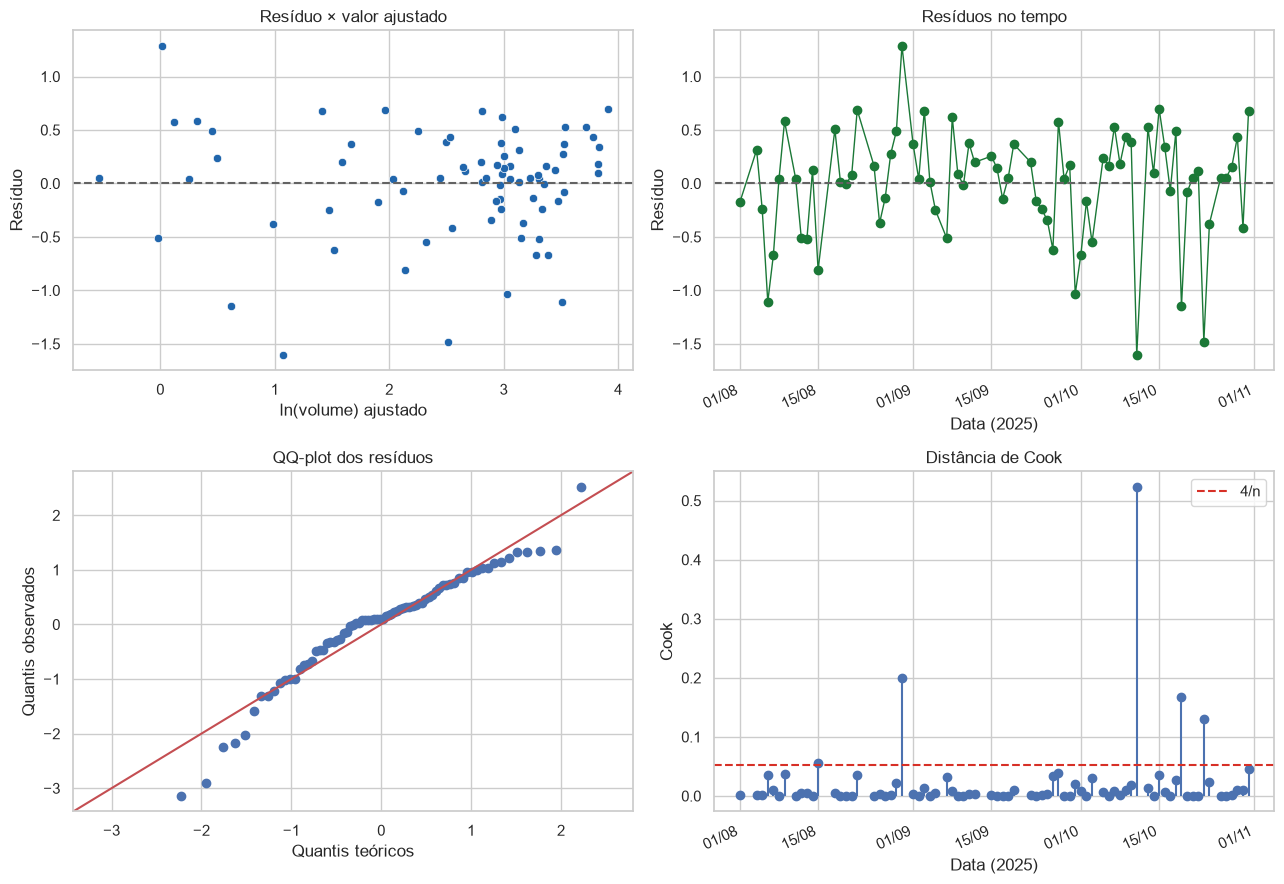

**Figura 2.3.** Resíduos, QQ-plot e influência no ajuste às 76 observações de desenvolvimento. Fonte: cálculo deste notebook; eixos indicam as unidades.

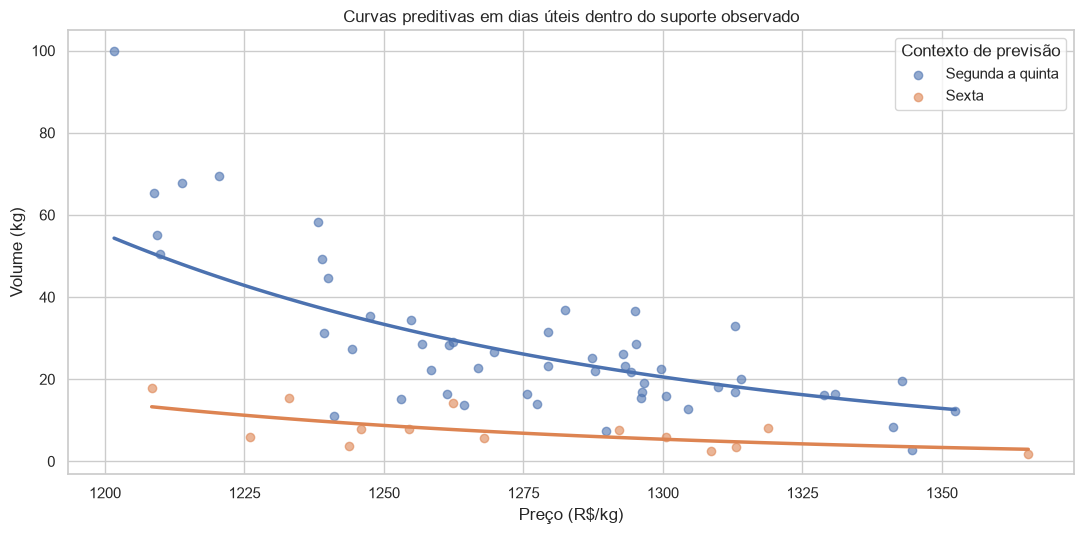

**Figura 2.4.** Curvas para os dois contextos de dias úteis; faixas observadas não garantem validade causal. Fonte: cálculo deste notebook; eixos indicam as unidades.

In [7]:
matriz_final = matriz_desenho(dados, ESPECIFICACAO)
residuos = modelo_final.resid
bp_lm, bp_p, _, _ = het_breuschpagan(residuos, matriz_final)
ljung_box = acorr_ljungbox(residuos, lags=[1, 5], return_df=True)
diagnosticos = pd.DataFrame({
    'Diagnóstico': [
        'Breusch-Pagan p-valor', 'Durbin-Watson',
        'Ljung-Box p-valor lag 1', 'Ljung-Box p-valor lag 5',
    ],
    'Resultado': [
        bp_p, float(durbin_watson(residuos)),
        ljung_box.loc[1, 'lb_pvalue'], ljung_box.loc[5, 'lb_pvalue'],
    ],
})
diagnosticos.to_csv(TABLES_DIR / 'diagnosticos_residuos.csv', index=False)
exibir_tabela(diagnosticos.round(4), 'Diagnósticos dos resíduos')

influencia = modelo_final.get_influence()
cook = influencia.cooks_distance[0]
alavancagem = influencia.hat_matrix_diag
nome_preco = modelo_final.model.exog_names[1]
elasticidade_loo = [
    float(ajustar(dados.drop(index=i), ESPECIFICACAO)[0].params[nome_preco]) for i in dados.index
]
coef_preco = float(modelo_final.params[nome_preco])
tabela_influencia = pd.DataFrame({
    'data': dados['data'], 'dia_semana': dados['dia_semana'],
    'volume_kg': dados['volume_kg'], 'preco_kg': dados['preco_kg'],
    'cook': cook, 'alavancagem': alavancagem, 'coef_preco_sem_observacao': elasticidade_loo,
})
tabela_influencia.to_csv(TABLES_DIR / 'influencia.csv', index=False)
limite_cook = 4 / len(dados)
limite_alavancagem = 2 * matriz_final.shape[1] / len(dados)
print(
    f'Cook > 4/n: {int((cook > limite_cook).sum())} observações | '
    f'alavancagem > 2p/n: {int((alavancagem > limite_alavancagem).sum())} observações'
)
print(
    f'Coeficiente de preço: completo {coef_preco:.2f}; sem uma observação, '
    f'de {min(elasticidade_loo):.2f} a {max(elasticidade_loo):.2f}'
)
exibir_tabela(tabela_influencia.nlargest(5, 'cook').round({'volume_kg': 3, 'preco_kg': 2, 'cook': 3, 'alavancagem': 3, 'coef_preco_sem_observacao': 3}), 'Observações com maior distância de Cook')

contexto_dev = dados['dia_semana'].map(MAPAS_CONTEXTO[ESPECIFICACAO['calendar']])
suporte_preco = (
    dados.loc[dados['dia_semana'].isin(DIAS_UTEIS)].assign(contexto=contexto_dev)
    .groupby('contexto')
    .agg(n=('preco_kg', 'size'), min=('preco_kg', 'min'), max=('preco_kg', 'max'))
    .reindex([c for c in ORDEM_CONTEXTO[ESPECIFICACAO['calendar']]
              if c in {MAPAS_CONTEXTO[ESPECIFICACAO['calendar']][d] for d in DIAS_UTEIS}])
)
suporte_preco.to_csv(TABLES_DIR / 'suporte_preco.csv')
exibir_tabela(suporte_preco.round(2), 'Faixas de preço observadas por contexto')

fig, eixos = plt.subplots(2, 2, figsize=(13, 9))
sns.scatterplot(x=modelo_final.fittedvalues, y=residuos, ax=eixos[0, 0], color='#2166ac')
eixos[0, 0].axhline(0, color='#636363', linestyle='--')
eixos[0, 0].set(title='Resíduo × valor ajustado', xlabel='ln(volume) ajustado', ylabel='Resíduo')
eixos[0, 1].plot(dados['data'], residuos, marker='o', linewidth=1, color='#1b7837')
eixos[0, 1].axhline(0, color='#636363', linestyle='--')
eixos[0, 1].set(title='Resíduos no tempo', xlabel='Data', ylabel='Resíduo')
sm.qqplot(residuos, line='45', fit=True, ax=eixos[1, 0])
eixos[1, 0].set(title='QQ-plot dos resíduos', xlabel='Quantis teóricos', ylabel='Quantis observados')
eixos[1, 1].stem(dados['data'], cook, basefmt=' ')
eixos[1, 1].axhline(limite_cook, color='#d73027', linestyle='--', label='4/n')
eixos[1, 1].set(title='Distância de Cook', xlabel='Data', ylabel='Cook')
eixos[1, 1].legend()
for eixo_data in [eixos[0, 1], eixos[1, 1]]:
    eixo_data.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=7))
    eixo_data.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m'))
    eixo_data.set_xlabel('Data (2025)')
    plt.setp(eixo_data.get_xticklabels(), rotation=25, ha='right')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'diagnosticos.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Resíduos, QQ-plot e influência no ajuste às 76 observações de desenvolvimento')

if ESPECIFICACAO['calendar'] == 'grouped':
    dia_representativo = {'Segunda_a_Quinta': 'Segunda', 'Sexta': 'Sexta', 'Fim_de_semana': 'Sábado'}
else:
    dia_representativo = {
        contexto: next(d for d, c in MAPAS_CONTEXTO[ESPECIFICACAO['calendar']].items() if c == contexto)
        for contexto in suporte_preco.index
    }
fig, ax = plt.subplots(figsize=(11, 5.5))
paleta = sns.color_palette('deep', len(suporte_preco))
for cor, (contexto, linha) in zip(paleta, suporte_preco.iterrows()):
    pontos = dados.loc[contexto_dev == contexto]
    ax.scatter(pontos['preco_kg'], pontos['volume_kg'], alpha=0.6, color=cor, label=contexto.replace('_', ' ').capitalize())
    grade = np.linspace(linha['min'], linha['max'], 100)
    base_curva = pd.DataFrame({
        'preco_kg': grade, 'ln_preco': np.log(grade),
        'dia_semana': dia_representativo[contexto], 'indice_tempo': 0,
    })
    ax.plot(grade, prever(modelo_final, smearing_final, base_curva, ESPECIFICACAO), color=cor, linewidth=2.5)
ax.set(title='Curvas preditivas em dias úteis dentro do suporte observado', xlabel='Preço (R$/kg)', ylabel='Volume (kg)')
ax.legend(title='Contexto de previsão')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'curvas_suporte.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Curvas para os dois contextos de dias úteis; faixas observadas não garantem validade causal')

**Resultado dos diagnósticos.** O Breusch–Pagan apresenta p = 0,0175, indicando evidência de
variância residual não constante no ajuste. Isso motiva os erros-padrão HC3, mas não demonstra
que um único smearing é suficiente em todo preço ou contexto. A calibração de dias úteis é
uma aproximação cuja qualidade foi avaliada fora da amostra nos folds.

Durbin–Watson é aproximadamente 1,83 e o Ljung–Box não indica autocorrelação residual curta
nos lags examinados. Esses resultados não garantem ausência de toda dependência temporal.
O QQ-plot e as medidas de influência mostram caudas e observações que merecem cautela.
A retirada de uma observação por vez conserva o sinal negativo da elasticidade, mas muda sua magnitude.

O suporte publicado contém 52 observações de segunda a quinta e 14 de sexta. O artefato de
previsão aceita somente esses dias e rejeita fins de semana; sua calibração não foi definida
para prever sábado ou domingo.

## 8. Congelamento e avaliação final no holdout

**Pergunta.** Como o modelo selecionado se comporta no conjunto reservado à avaliação final?

**Método.** Primeiro são salvos os coeficientes, o smearing dos dias úteis, o calendário admitido,
o suporte, a regra de escolha e os hashes de integridade. Só depois o holdout é carregado para
calcular as métricas e comparar previsto e observado. Uma perda relevante de desempenho pode
motivar investigação e revisão do modelo.

**Alcance do congelamento.** A sequência de execução salva o artefato antes de carregar o holdout e impede alterações posteriores nessa mesma execução. O hash comprova identidade de conteúdo; não certifica que versões anteriores do projeto nunca consultaram essas datas. Os números de novembro são uma avaliação histórica reservada pelo protocolo, não evidência de um teste prospectivo independente. Se forem usados para escolher uma revisão do modelo, sua avaliação final exigirá novas observações.

In [8]:
spec = ESPECIFICACAO
nomes = list(modelo_final.model.exog_names)
mapa_publicado = {dia: MAPAS_CONTEXTO[spec['calendar']][dia] for dia in DIAS_UTEIS}
contextos_publicados = [c for c in ORDEM_CONTEXTO[spec['calendar']] if c in set(mapa_publicado.values())]
artefato = {
    'artifact_version': 2,
    'model_id': f'{ESCOLHIDO}-{spec["family"]}-{spec["calendar"]}-dias-uteis',
    'family': spec['family'],
    'calendar': {
        'baseline': ORDEM_CONTEXTO[spec['calendar']][0],
        'contexts': contextos_publicados, 'mapping': mapa_publicado,
        'source_variable': 'dia_semana',
    },
    'feature_order': nomes,
    'coefficients': {nome: float(modelo_final.params[nome]) for nome in nomes},
    'smearing_factor': smearing_final,
    'smearing_calibration': {
        'method': 'mean_exp_log_residuals_on_weekdays', 'rows': n_smearing,
        'weekdays': DIAS_UTEIS, 'source': 'training_residuals_only',
    },
    'price_support': {
        contexto: {'min': float(l['min']), 'max': float(l['max']), 'n': int(l['n'])}
        for contexto, l in suporte_preco.iterrows()
    },
    'formula': 'ln(volume_kg) ~ ln(preco_kg) + calendario' if spec['family'] == 'power'
    else 'ln(volume_kg) ~ preco_kg/100 + calendario',
    'training': {
        'data_file': 'data/processed/minerva_modelagem_treino.csv',
        'data_sha256': file_sha256(DATA_PATH), 'rows': int(len(dados)),
        'start': str(dados['data'].min().date()), 'end': str(dados['data'].max().date()),
        'coefficient_estimation_domain': 'all_observations',
    },
    'selection': {
        'protocol': 'expanding_window_weekly_origins_two_week_horizon_weekdays',
        'primary_metric': 'WMAPE_daily', 'folds': len(origens),
        'origins': [str(o.date()) for o in origens],
        'evaluated_weekdays': DIAS_UTEIS, 'horizon_calendar_days': HORIZONTE_DIAS,
        'candidates_compared': CONCORRENTES, 'chosen': ESCOLHIDO,
        'wmape_daily_mean': float(painel.loc[ESCOLHIDO, 'WMAPE diário (%)'] / 100),
        'wmape_weekly_mean': float(painel.loc[ESCOLHIDO, 'WMAPE semanal (%)'] / 100),
        'rmse_mean': float(painel.loc[ESCOLHIDO, 'RMSE (kg)']),
        'daily_equivalence_pp': 100 * ZONA_WMAPE_DIARIO,
        'rmse_relative_tolerance': ZONA_RMSE,
    },
    'diagnostics': {
        'breusch_pagan_p_value': float(bp_p), 'durbin_watson': float(durbin_watson(residuos)),
        'ljung_box_p_value_lag_5': float(ljung_box.loc[5, 'lb_pvalue']),
    },
    'observational_warning': (
        'Curva preditiva observacional para dias uteis; preco pode refletir demanda '
        'antecipada e variaveis omitidas. Nao interpretar como efeito causal identificado.'
    ),
}
artefato['model_core_sha256'] = model_core_sha256(artefato)
validate_artifact(artefato)
save_artifact(artefato, MODELO_PATH)
hash_congelado = artefato['model_core_sha256']
arquivo_congelado_hash = file_sha256(MODELO_PATH)
assert set(artefato['calendar']['mapping']) == set(DIAS_UTEIS)
print(f'Modelo salvo em {MODELO_PATH.relative_to(ROOT)}')
print(f'Hash do núcleo: {hash_congelado}')

Modelo salvo em models/preditivo_diario/curva_demanda.json
Hash do núcleo: d5b658c7654bee68f0cd706d7a75b846c0a41d9fe542e66f326a80fb6daa0385


**Tabela 2.9.** Métricas do holdout: erros em kg e percentuais. Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,WMAPE diário (%),MAE (kg),RMSE (kg),Viés (%),WMAPE semanal (%)
0,37.236,6.838,8.676,-18.548,18.548


**Tabela 2.10.** Volumes observados e previstos por semana no holdout (kg). Unidades indicadas nas colunas; fonte: cálculo deste notebook.

,volume_real_kg,volume_previsto_kg,erro_kg,erro_%
inicio_semana,,,,
2025-11-03,74.241,72.670,-1.571,-2.116
2025-11-10,109.388,76.899,-32.489,-29.701


Preços fora do suporte: nenhum
Diferença máxima entre previsão do notebook e inferência do artefato: 1.35e-13 kg
Artefato preservado após a leitura do holdout: True


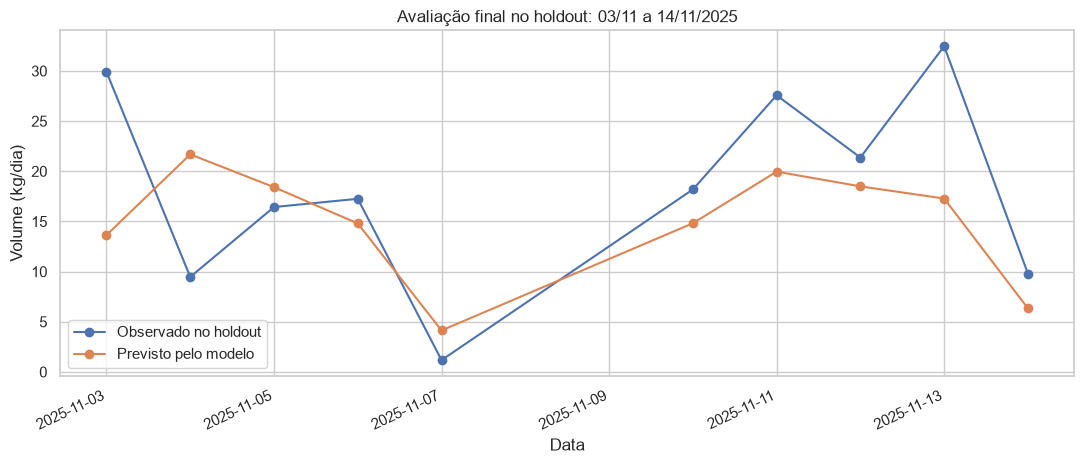

**Figura 2.5.** Volume observado e previsto nos preços praticados nos dez dias úteis do holdout histórico. Fonte: cálculo deste notebook; eixos indicam as unidades.

In [9]:
holdout_raw = pd.read_csv(HOLDOUT_PATH, parse_dates=['Data']).sort_values('Data')
holdout = pd.DataFrame({
    'data': holdout_raw['Data'],
    'volume_real_kg': holdout_raw['Volume Realizado (kg)'].astype(float),
    'preco_kg': holdout_raw['Receita Realizada (R$)'] / holdout_raw['Volume Realizado (kg)'],
}).reset_index(drop=True)
holdout['numero_dia_semana'] = holdout['data'].dt.dayofweek
holdout['dia_semana'] = holdout['numero_dia_semana'].map(dict(enumerate(ORDEM_DIAS)))
holdout['inicio_semana'] = holdout['data'] - pd.to_timedelta(holdout['numero_dia_semana'], unit='D')
holdout['contexto'] = holdout['dia_semana'].map(mapa_publicado)
holdout['ln_preco'] = np.log(holdout['preco_kg'])
assert holdout['dia_semana'].isin(DIAS_UTEIS).all()
assert holdout['data'].min() > dados['data'].max()
holdout['volume_previsto_kg'] = prever(modelo_final, smearing_final, holdout, spec)
holdout['erro_kg'] = holdout['volume_previsto_kg'] - holdout['volume_real_kg']

fora_do_suporte = [
    (str(l.data.date()), round(l.preco_kg, 2)) for l in holdout.itertuples()
    if not suporte_preco.loc[l.contexto, 'min'] <= l.preco_kg <= suporte_preco.loc[l.contexto, 'max']
]
metricas_holdout = painel_erros(holdout)
semanal_holdout = holdout.groupby('inicio_semana')[['volume_real_kg', 'volume_previsto_kg']].sum()
semanal_holdout['erro_kg'] = semanal_holdout['volume_previsto_kg'] - semanal_holdout['volume_real_kg']
semanal_holdout['erro_%'] = 100 * semanal_holdout['erro_kg'] / semanal_holdout['volume_real_kg']

via_modulo = np.array([
    predict_volume_from_artifact(MODELO_PATH, p, dia, allow_extrapolation=True)
    for p, dia in zip(holdout['preco_kg'], holdout['dia_semana'])
])
diferenca_modulo = float(np.max(np.abs(via_modulo - holdout['volume_previsto_kg'])))
assert diferenca_modulo < 1e-10
assert file_sha256(MODELO_PATH) == arquivo_congelado_hash
assert model_core_sha256(json.loads(MODELO_PATH.read_text(encoding='utf-8'))) == hash_congelado
for dia_fora_dominio in ['Sábado', 'Domingo']:
    try:
        predict_volume_from_artifact(MODELO_PATH, 1300, dia_fora_dominio)
    except ValueError:
        pass
    else:
        raise AssertionError('O domínio publicado deve rejeitar fins de semana.')

holdout.to_csv(TABLES_DIR / 'previsoes_holdout.csv', index=False)
semanal_holdout.to_csv(TABLES_DIR / 'resumo_semanal_holdout.csv')
resumo_holdout = pd.DataFrame([{
    'WMAPE diário (%)': 100 * metricas_holdout['WMAPE diário'],
    'MAE (kg)': metricas_holdout['MAE'], 'RMSE (kg)': metricas_holdout['RMSE'],
    'Viés (%)': 100 * metricas_holdout['Viés'],
    'WMAPE semanal (%)': 100 * metricas_holdout['WMAPE semanal'],
}])
resumo_holdout.to_csv(TABLES_DIR / 'metricas_holdout.csv', index=False)
exibir_tabela(resumo_holdout.round(3), 'Métricas do holdout: erros em kg e percentuais')
exibir_tabela(semanal_holdout.round(3), 'Volumes observados e previstos por semana no holdout (kg)')
print(f'Preços fora do suporte: {fora_do_suporte or "nenhum"}')
print(f'Diferença máxima entre previsão do notebook e inferência do artefato: {diferenca_modulo:.2e} kg')
print(f'Artefato preservado após a leitura do holdout: {file_sha256(MODELO_PATH) == arquivo_congelado_hash}')

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(holdout['data'], holdout['volume_real_kg'], marker='o', label='Observado no holdout')
ax.plot(holdout['data'], holdout['volume_previsto_kg'], marker='o', label='Previsto pelo modelo')
ax.set(title='Avaliação final no holdout: 03/11 a 14/11/2025', xlabel='Data', ylabel='Volume (kg/dia)')
ax.legend()
fig.autofmt_xdate(rotation=25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'holdout.png', dpi=160, bbox_inches='tight')
plt.show()
legendar_figura('Volume observado e previsto nos preços praticados nos dez dias úteis do holdout histórico')

## 9. Resultado do holdout

O modelo apresenta **WMAPE diário de 37,24%**, MAE de **6,84 kg**, RMSE de **8,68 kg**, viés de
**−18,55%** e WMAPE semanal de **18,55%** nos dez dias úteis do holdout. O WMAPE diário está
próximo da média de **36,85%** na validação cruzada temporal, mas os períodos e a quantidade de
observações são diferentes; essa proximidade não demonstra estabilidade futura.

- **Semana de 03/11:** 72,67 kg previstos e 74,24 kg observados; erro do total de −2,12%.
- **Semana de 10/11:** 76,90 kg previstos e 109,39 kg observados; erro do total de −29,70%.

As duas semanas são subestimadas, com a maior diferença na segunda. O WMAPE semanal coincide
com o módulo do viés agregado porque os erros dos dois totais têm o mesmo sinal. Isso não
significa ausência de compensação entre erros diários dentro de cada semana.

Todos os preços do holdout estão dentro do suporte de seus contextos. O arquivo do modelo
permanece idêntico ao salvo antes da leitura, e a inferência do módulo reproduz a previsão do
notebook com diferença inferior a 10⁻¹⁰ kg. A avaliação não cobre fins de semana nem identifica
o efeito causal de mudar preços.

### Conclusões e limites

1. A seleção é baseada em **WMAPE diário na validação cruzada temporal**, com seis folds de
   origem semanal e horizonte de duas semanas, avaliando somente os dias úteis.
2. `P3` é selecionado pela regra de equivalência prática e interpretação da potência. A escolha
   não pressupõe superioridade estatística em relação a `E1`.
3. Os coeficientes usam todas as 76 observações de desenvolvimento; o smearing é calculado nos
   66 resíduos dos dias úteis. O domínio publicado admite somente segunda a sexta.
4. O WMAPE semanal permanece complementar para avaliar os totais associados às metas. Ele não
   substitui a avaliação da distribuição diária do volume.
5. A elasticidade tem sinal negativo e magnitude incerta. Há heterogeneidade residual e observações
   influentes; uma única correção de retransformação para dias úteis é uma aproximação.
6. O modelo e seus metadados são gravados antes da avaliação final no holdout.

As hipóteses de calendário foram formuladas com o desenvolvimento, e a comparação é condicional
a esse catálogo. Os horizontes dos folds se sobrepõem, há somente seis origens e o holdout
contém apenas duas semanas. Essas limitações impedem interpretar pequenas diferenças de médias
como prova de superioridade ou generalizar a avaliação para outros períodos e dias da semana.
A associação entre preço e volume permanece observacional.

## 10. Artefatos do estudo

| Local | Conteúdo |
|---|---|
| `models/preditivo_diario/curva_demanda.json` | Modelo, domínio de dias úteis, smearing, seleção, suporte e hashes |
| `reports/tables/preditivo_diario/calendario_validacao_cruzada.csv` | Calendário e tamanhos de ajuste e avaliação por fold |
| `reports/tables/preditivo_diario/comparacao_candidatos.csv` | Painel de métricas e aplicação da regra |
| `reports/tables/preditivo_diario/metricas_validacao_cruzada.csv` | Indicadores por candidato e fold |
| `reports/tables/preditivo_diario/previsoes_validacao_cruzada.csv` | Previsões com origem e data final de ajuste |
| `reports/tables/preditivo_diario/parametros_por_fold.csv` | Inclinação, smearing e quantidade de resíduos por ajuste |
| `reports/tables/preditivo_diario/coeficientes_ajuste_final.csv` | Coeficientes e intervalos HC3 |
| `reports/tables/preditivo_diario/diagnosticos_residuos.csv`, `influencia.csv`, `suporte_preco.csv` | Diagnósticos e suporte |
| `reports/tables/preditivo_diario/metricas_holdout.csv`, `previsoes_holdout.csv`, `resumo_semanal_holdout.csv` | Avaliação final |
| `reports/figures/preditivo_diario/` | Folds, candidatos, diagnósticos, curvas e holdout |



## Referências metodológicas

- MINERVA FOODS; UNIFESP; ITA. *Otimização de precificação aplicado ao segmento de carnes in natura: Desafio Minerva-Unifesp-ITA*. 17 ago. 2026. [Enunciado](../docs/referencias/Minerva_Unifesp_ITA.pdf).
- PHILLIPS, Robert L. *Pricing and Revenue Optimization*. 2. ed. Stanford: Stanford University Press, 2021. cap. 4, seções 4.2 a 4.4. [Dados bibliográficos e fontes](../docs/referencias-bibliograficas.md).
- DUAN, Naihua. Smearing Estimate: A Nonparametric Retransformation Method. *Journal of the American Statistical Association*, 78(383), 605–610, 1983. [DOI](https://doi.org/10.1080/01621459.1983.10478017).
- MACKINNON, James G.; WHITE, Halbert. Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. *Journal of Econometrics*, 29(3), 305–325, 1985. [DOI](https://doi.org/10.1016/0304-4076(85)90158-7).
- HYNDMAN, Rob J.; ATHANASOPOULOS, George. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts, 2021. cap. 5, seções 5.2 e 5.10. [Texto](https://otexts.com/fpp3/toolbox.html).
- GUROBI OPTIMIZATION, LLC. *Gurobi Optimizer Reference Manual*, versão 13.0. Seção Nonlinear Constraints. [Documentação](https://docs.gurobi.com/projects/optimizer/en/current/features/nonlinear.html).

O enunciado e a planilha são as fontes das regras. As tabelas exportadas por este notebook são as fontes dos resultados próprios. Cenários escolhidos pelo grupo são premissas de análise, sem respaldo atribuído a uma fonte externa. A revisão comparativa de Mullapudi, citada pelo enunciado, não é usada como fonte dos métodos estatísticos ou do solver e não integra esta bibliografia.
